# Welcome to the RandQuantKry Visualizations Notebook

This notebook is for all those who have mastered the tutorials and are looking for fun ways to visualize their results. This is the tutorials for **RandQuantKry** can be found <a href="scripts/"><b>scripts/</b></a> in the respectively named Jupyter Notebooks. Happy visualizing. :)

In [ ]:
# imports
import numpy as np
import pandas as pd
from scipy.linalg import expm
from pathlib import Path
# matplotlib imports
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
import matplotlib.colors as mcolors
import matplotlib as mpl
# animation
import imageio_ffmpeg

# these files can be found in src/ and are the main building blocks of this package
from randquantkry.hamiltonian import build_hamiltonian
from randquantkry.evolution import time_evolve_naive, time_evolve_krylov, time_evolve_randomized_krylov
from randquantkry.benchmark import Benchmark
from randquantkry.post_processing import plot_parameter_study, plot_memory, plot_runtime
# utils/ contains all helper functions that allow for example logging
from randquantkry.utils.logging_config import configure_logging, get_logger
from randquantkry.utils.reproducible_runs import load_run, start_run, append_result_row
from randquantkry.utils.meta_metadata_file_generator import build_run_index

In [2]:
log = get_logger(__name__)
configure_logging(console_level='INFO')

11:03:52 | INFO     | randquantkry | logging configured (console only)


<Logger randquantkry (DEBUG)>

### Prepare Data 

In [3]:
# from the notebook, go up to repo root explicitly
repo_root = Path.cwd().parent  # if notebook is one level inside repo root, e.g. scripts/
results_dir = repo_root / "results" 

In [4]:
output_dir = results_dir / "run_20260725T182937Z" # <-- your unique run ID here
plot_dir = Path(output_dir) / "plots"
plot_dir.mkdir(
            parents=True, exist_ok=True
        )


In [5]:
df, meta = load_run(output_dir)

## Part 1: Visualizing Parameter Study

One plot with a lot of information.

In [6]:
# Reorganize results dataframe
df_kry = df[df["method"] == "krylov"].copy()
df_rkry = df[df["method"] == "randomized_krylov"].copy()
groups = sorted(df_kry['krylov_dim'].unique())  # e.g. [12, 24, 48]


# Build boundaries halfway between each group value, so each group gets its own color bin
boundaries = [groups[0] - (groups[1]-groups[0])/2]
for i in range(len(groups)-1):
    boundaries.append((groups[i] + groups[i+1]) / 2)
boundaries.append(groups[-1] + (groups[-1]-groups[-2])/2)

11:06:58 | INFO     | randquantkry.__main__ | Saved 'Krylov_err_vs_time.png' successfully! | {'context': {'run_dir': 'c:\\Users\\feaus\\GIT\\randquantkry-1\\results\\run_20260725T182937Z\\plots'}}


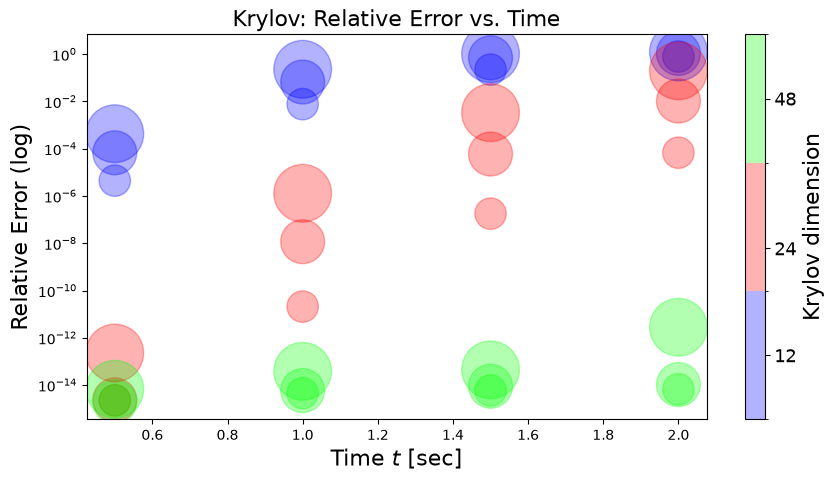

In [16]:

cmap = plt.colormaps['brg'].resampled(len(groups))
norm = mcolors.BoundaryNorm(boundaries, cmap.N)

plt.figure(figsize=(10, 5))
sc = plt.scatter(
    df_kry['time'],
    df_kry['rel_error'],
    s=df_kry['n_qubits']**3,
    c=df_kry['krylov_dim'],
    cmap=cmap,
    norm=norm,
    alpha=0.3
)

plt.yscale('log')
plt.xlabel("Time $t$ [sec]", fontsize=16)
plt.ylabel("Relative Error (log)", fontsize=16)
plt.title("Krylov: Relative Error vs. Time", fontsize=16)

cbar = plt.colorbar(sc, ticks=groups)
cbar.set_label("Krylov dimension", fontsize=16)
cbar.ax.tick_params(labelsize=13)

# plt.show()
plt.savefig(plot_dir/"Krylov_err_vs_time.png", dpi=300)

log.info("Saved 'Krylov_err_vs_time.png' successfully!", extra={"context": {"run_dir": str(plot_dir),
}})

## Part 2: Visualizing Dimensions

The motivation behind this visualization is to make the concept behind the different dimension parameter choices easier to understand. However this very cool visualization requires more information and more runs than normally performed, so it is necessary to rerun the simulations.

Set up hamiltonian, the time steps, the krylov dimensions (or randomized krylov dimensions) and colors for the runs:

In [8]:
# old hamiltonian 
n_qubits = 8
rng = np.random.default_rng(0)
seed = 67

terms = []
for i in range(n_qubits):
    terms.append(('X', i, float(rng.uniform(0.5, 1.5))))       # X field, every qubit
for i in range(n_qubits - 1):
    terms.append(('ZZ', i, float(rng.uniform(0.3, 0.8))))      # ZZ coupling, every neighboring pair

hamiltonian = build_hamiltonian(n_qubits, terms)
n_qubits = hamiltonian.num_qubits
initial_state = np.zeros(2**n_qubits, dtype=complex)
initial_state[128] = 1.0   

11:03:52 | INFO     | randquantkry.hamiltonian | build_hamiltonian: built | {'context': {'n_qubits': 8, 'matrix_dim': 256, 'n_terms': 15}}


In [9]:
time_steps = np.linspace(0.0, 5.0, 300)
k_list = [3, 12, 40]
colors = ["#ff2929", '#fbbf24', "#24e22b", "#7248f0"]  # Red, Yellow, Green, Purple


In [10]:
# Fix FFmpeg path if needed
mpl.rcParams['animation.ffmpeg_path'] = imageio_ffmpeg.get_ffmpeg_exe()

In [11]:
run_config = {
    "k_list": list(k_list),
    "time_steps": list(time_steps),
    "n_qubits": n_qubits,
    "seed": seed,
}

results_dir = repo_root / "results" / "visualizations"
run_dir = start_run(results_dir, run_config)
configure_logging(json_path=run_dir / "run.log.jsonl", console_level="INFO")

log.info("trajectory_viz: starting", extra={"context": {
    "run_dir": str(run_dir), "k_list": list(k_list), "n_times": len(time_steps),
}})


11:03:52 | INFO     | randquantkry | logging configured | {'context': {'json_path': 'c:\\Users\\feaus\\GIT\\randquantkry-1\\results\\visualizations\\run_20260730T090352Z\\run.log.jsonl'}}
11:03:52 | INFO     | randquantkry.__main__ | trajectory_viz: starting | {'context': {'run_dir': 'c:\\Users\\feaus\\GIT\\randquantkry-1\\results\\visualizations\\run_20260730T090352Z', 'k_list': [3, 12, 40], 'n_times': 300}}


In [12]:
# Compute exact trajectory
true_states = []
for t in time_steps:
    _, psi_t = time_evolve_naive(hamiltonian, initial_state, t)
    true_states.append(psi_t)

log.info("trajectory_viz: exact trajectory computed", extra={"context": {"n_times": len(true_states)}})

# We fix the projection basis V to a reference dimension (e.g., max k) for 3D visualization
k_max = max(k_list)
_, V_full, _ = time_evolve_krylov(hamiltonian, initial_state, 0.0, k_max, instrumental=True)
V_proj = np.array(V_full)[:3]  # Use first 3 basis vectors for 3D coordinate space

# Project True State into this fixed 3D basis:
true_coeffs = np.abs(np.array([V_proj @ psi for psi in true_states]))[:, :3]  # (T, 3)

# Find the 3 computational basis states with the most average population
avg_pop = np.mean([np.abs(psi)**2 for psi in true_states], axis=0)  # shape (256,)
top3_idx = np.argsort(avg_pop)[-3:][::-1]
log.info("trajectory_viz: top3 basis states", extra={"context": {
    "top3_idx": [int(i) for i in top3_idx],
    "top3_bin": [format(int(i), '08b') for i in top3_idx],
}})


# Now "projection" is trivial: just read off those amplitudes directly
true_coeffs = np.abs(np.array([[psi[i] for i in top3_idx] for psi in true_states]))

approx_trajectories = {}
rel_errors = {}
for k in k_list:
    _, V_k, Tri_k = time_evolve_krylov(hamiltonian, initial_state, 0.0, k, instrumental=True)
    V_k = np.array(V_k)[:Tri_k.shape[0]]

    e1 = np.zeros(Tri_k.shape[0], dtype=complex)
    e1[0] = 1.0
    coeffs_k = []
    errs_k = []

    for idx, t in enumerate(time_steps):
        y_t = expm(-1j * Tri_k * t) @ e1
        psi_approx = V_k.T @ y_t

        coeffs_k.append([psi_approx[i] for i in top3_idx])

        num = np.linalg.norm(psi_approx - true_states[idx])
        den = np.linalg.norm(true_states[idx])
        err = num / den
        errs_k.append(err)

        # incremental persistence, mirroring append_result_row in parameter_study
        row = {
            "k": int(k),
            "time_idx": int(idx),
            "time": float(t),
            "coeff_0": complex(psi_approx[top3_idx[0]]).real,
            "coeff_1": complex(psi_approx[top3_idx[1]]).real,
            "coeff_2": complex(psi_approx[top3_idx[2]]).real,
            "rel_error": float(err),
        }
        append_result_row(run_dir, row)

    approx_trajectories[k] = np.abs(np.array(coeffs_k))
    rel_errors[k] = np.array(errs_k)

    log.info("trajectory_viz: k done", extra={"context": {
        "k": int(k), "final_rel_error": float(errs_k[-1]) if errs_k else None,
    }})

log.info("trajectory_viz: complete", extra={"context": {
    "n_k": len(k_list), "run_dir": str(run_dir),
}})

11:03:52 | INFO     | randquantkry.evolution | time_evolve_naive: starting | {'context': {'n_qubits': 8, 'matrix_dim': 256, 'time': np.float64(0.0)}}
11:03:52 | INFO     | randquantkry.evolution | time_evolve_naive: complete | {'context': {'evolved_state_norm': 1.0000000000000004}}
11:03:52 | INFO     | randquantkry.evolution | time_evolve_naive: starting | {'context': {'n_qubits': 8, 'matrix_dim': 256, 'time': np.float64(0.016722408026755852)}}
11:03:52 | INFO     | randquantkry.evolution | time_evolve_naive: complete | {'context': {'evolved_state_norm': 1.0}}
11:03:52 | INFO     | randquantkry.evolution | time_evolve_naive: starting | {'context': {'n_qubits': 8, 'matrix_dim': 256, 'time': np.float64(0.033444816053511704)}}
11:03:52 | INFO     | randquantkry.evolution | time_evolve_naive: complete | {'context': {'evolved_state_norm': 1.0}}
11:03:52 | INFO     | randquantkry.evolution | time_evolve_naive: starting | {'context': {'n_qubits': 8, 'matrix_dim': 256, 'time': np.float64(0.05

In [13]:
# Setup 3D Plot
fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(111, projection="3d")

ax.set_title("Convergence of Krylov Approximations vs. State Vector dimensions", fontsize=18, pad=15)
top3_bin =  [format(i, '08b') for i in top3_idx]
ax.set_xlabel(fr"$|{top3_bin[0]}\rangle$", fontsize=18)
ax.set_ylabel(fr"$|{top3_bin[1]}\rangle$", fontsize=18)
ax.set_zlabel(fr"$|{top3_bin[2]}\rangle$", fontsize=18)

# Set Axis Limits based on all trajectories combined
all_pts = [true_coeffs] + [approx_trajectories[k] for k in k_list]
combined_pts = np.vstack(all_pts)
ax.set_xlim(combined_pts[:, 0].min(), combined_pts[:, 0].max())
ax.set_ylim(combined_pts[:, 1].min(), combined_pts[:, 1].max())
ax.set_zlim(combined_pts[:, 2].min(), combined_pts[:, 2].max())

# Create Plot Artists:
# Exact State (Blue Solid Line)
trail_true, = ax.plot([], [], [], color='#3b82f6', lw=3, label="True State (Exact)")
point_true, = ax.plot([], [], [], 'o', color='#3b82f6', ms=8)

# Krylov Approximations for each k
trails_approx = {}
points_approx = {}

for k, color in zip(k_list, colors):
    t_line, = ax.plot([], [], [], ls='--', lw=1.8, color=color, label=f"Krylov $k={k}$")
    p_line, = ax.plot([], [], [], 's', ms=6, color=color)
    trails_approx[k] = t_line
    points_approx[k] = p_line

ax.legend(loc="upper left", fontsize=16)

# Animation Update Function
def update(frame):
    # Update True State
    trail_true.set_data(true_coeffs[:frame + 1, 0], true_coeffs[:frame + 1, 1])
    trail_true.set_3d_properties(true_coeffs[:frame + 1, 2])
    point_true.set_data([true_coeffs[frame, 0]], [true_coeffs[frame, 1]])
    point_true.set_3d_properties([true_coeffs[frame, 2]])

    # Update Approximations for each k
    artists = [trail_true, point_true]
    for k in k_list:
        data_k = approx_trajectories[k]
        trails_approx[k].set_data(data_k[:frame + 1, 0], data_k[:frame + 1, 1])
        trails_approx[k].set_3d_properties(data_k[:frame + 1, 2])
        
        points_approx[k].set_data([data_k[frame, 0]], [data_k[frame, 1]])
        points_approx[k].set_3d_properties([data_k[frame, 2]])
        
        artists.extend([trails_approx[k], points_approx[k]])

    # Optional: Slowly rotate camera for a dynamic 3D effect
    # ax.view_init(elev=20, azim=0.5 * frame)

    return artists

# ---- 6. Render & Save Animation ----
anim = FuncAnimation(fig, update, frames=len(time_steps), interval=40, blit=False)

# Save MP4
plt.tight_layout()
writer = FFMpegWriter(fps=25, metadata=dict(artist='Me'), bitrate=2000)
anim.save(run_dir/"multi_k_psi_convergence.mp4", writer=writer)
plt.close()

log.info("Saved 'multi_k_psi_convergence.mp4' successfully!", extra={"context": {"run_dir": str(run_dir),
}})

11:05:04 | INFO     | randquantkry.__main__ | Saved 'multi_k_psi_convergence.mp4' successfully! | {'context': {'run_dir': 'c:\\Users\\feaus\\GIT\\randquantkry-1\\results\\visualizations\\run_20260730T090352Z'}}


In [14]:
fig, ax = plt.subplots(figsize=(9, 3.5))

ax.set_title("Relative Error vs. Time", fontsize=18, pad=15)
ax.set_xlabel("Time $t$ [sec]", fontsize=14)
ax.set_ylabel("Relative Error", fontsize=14)
ax.set_yscale("log")
ax.set_xlim(time_steps[0], time_steps[-1])

err_min = min(rel_errors[k][rel_errors[k] > 0].min() for k in k_list)
err_max = max(rel_errors[k].max() for k in k_list)
ax.set_ylim(err_min * 0.5, err_max * 2)
ax.grid(True, which="both", alpha=0.25)

lines, points = {}, {}
for k, color in zip(k_list, colors):
    line, = ax.plot([], [], color=color, lw=2, label=f"Krylov $k={k}$")
    pt, = ax.plot([], [], "o", color=color, ms=6)
    lines[k] = line
    points[k] = pt

ax.legend(loc="lower right", fontsize=14)
plt.tight_layout()

# Animation update function ----
def update(frame):
    artists = []
    for k in k_list:
        err_k = rel_errors[k]
        lines[k].set_data(time_steps[: frame + 1], err_k[: frame + 1])
        points[k].set_data([time_steps[frame]], [err_k[frame]])
        artists += [lines[k], points[k]]
    return artists

# Render & save ----
anim = FuncAnimation(fig, update, frames=len(time_steps), interval=40, blit=False)

writer = FFMpegWriter(fps=25, metadata=dict(artist="Me"), bitrate=2000)
anim.save(run_dir /"rel_error_convergence.mp4", writer=writer, dpi=140)
plt.close()

print("Saved 'rel_error_convergence.mp4' successfully!")

log.info("Saved 'rel_error_convergence.mp4' successfully!", extra={"context": {"run_dir": str(run_dir),
}})

11:06:01 | INFO     | randquantkry.__main__ | Saved 'rel_error_convergence.mp4' successfully! | {'context': {'run_dir': 'c:\\Users\\feaus\\GIT\\randquantkry-1\\results\\visualizations\\run_20260730T090352Z'}}


Saved 'rel_error_convergence.mp4' successfully!
